# Adjusting hyperparameter for model
In this notebook we will use the Decision tree to model a classification dataset. Using the Diabetes dataset from the Pima population, we will generate a Decision tree and fine tune it on our training set. This notebook will cover splitting data, decision tree, cross validation and grid search.

In [1]:
# Load libraries
# !pip install six
import pandas as pd
from sklearn.tree import DecisionTreeClassifier # Import Decision Tree Classifier
from sklearn.model_selection import train_test_split # Import train_test_split function
from sklearn import metrics #Import scikit-learn metrics module for accuracy calculation
from six import StringIO  # in place of StringIO
from sklearn.tree import export_graphviz
import pydotplus
# from io import StringIO  # Use io.StringIO directly. No longer supported in versions python 2.4 +
from PIL import Image  # Use PIL or IPython.display.Image for Jupyter Notebooks
from IPython.display import Image  # Optional, for Jupyter



### Load diabetes data
Pima Indians Diabetes Database from [kaggle](https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database?resource=download)
We will follow the tutorial from [Data camp](https://www.datacamp.com/tutorial/decision-tree-classification-python)

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


: 

In [ ]:
## finding path
# !ls drive/MyDrive/SJSU/SJSU_Spring2026/CS133/Activity/Module07_ml

: 

In [ ]:
# gdrive='drive/MyDrive/SJSU/SJSU_Spring2026/CS133/Activity/Module07_ml/'
# fp=gdrive+'diabetes.csv'

: 

### Pima Diabetes dataset

In [4]:
col_names = ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']

fp = "diabetes.csv"

## Load dataset
pima = pd.read_csv(fp, header=None, names=col_names)
pima = pima.drop(index=pima.index[0])
pima.head()

,pregnant,glucose,bp,skin,insulin,bmi,pedigree,age,label
1,6,148,72,35,0,33.6,0.627,50,1
2,1,85,66,29,0,26.6,0.351,31,0
3,8,183,64,0,0,23.3,0.672,32,1
4,1,89,66,23,94,28.1,0.167,21,0
5,0,137,40,35,168,43.1,2.288,33,1


**Feature Selection**  
Divide given columns into two types of variables dependent(or target variable) and independent variable(or feature variables).

In [5]:
#split dataset in features and target variable
# ['pregnant', 'glucose', 'bp', 'skin', 'insulin', 'bmi', 'pedigree', 'age', 'label']
feature_cols = ['pregnant', 'insulin', 'bmi', 'age','glucose','bp','pedigree']
X = pima[feature_cols] # Features
y = pima.label # Target variable


**Splitting Data**  
To understand model performance, dividing the dataset into a training set and a test set is a good strategy.
  
Let's split the dataset by using the function train_test_split(). You need to pass three parameters features; target, and test_set size.




In [6]:
# Split dataset into training set and test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) 

**Building Decision Tree Model**  
Let's create a decision tree model using Scikit-learn [`DecisionTreeClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html).

In [10]:
### Create Decision Tree classifer object
clf = DecisionTreeClassifier()

### Train Decision Tree Classifer
clf = clf.fit(X_train, y_train)

### Predict the response for test dataset
y_pred = clf.predict(X_test)

In [14]:
from sklearn.model_selection import cross_val_score
# cross_val_score(<classifier object>, X, y, <cv>)
score = cross_val_score(clf, X_train, y_train, cv=10)
print("cv scores:", score)
print("cv avg:", score.mean())

cv scores: [0.69354839 0.69354839 0.66129032 0.75806452 0.60655738 0.75409836
 0.72131148 0.72131148 0.68852459 0.73770492]
cv avg: 0.7035959809624537


**Evaluating the Model**  
Let's estimate how accurately the classifier or model can predict the type of cultivars. Accuracy can be computed by comparing actual test set values and predicted values.

We will use the function `metrics.accuracy_score(y_test, y_pred)`. This function evaluates the performance of classification model by calculating the proportion of correct predictions out of the total number of samples
  
This function found an accuracy of 67.53% for the classification rate, which is considered as good accuracy. You can improve this accuracy by tuning the parameters in the decision tree algorithm.

In [15]:
# Model Accuracy, how often is the classifier correct?
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.7532467532467533


**Visualizing Decision Trees**  
You can use Scikit-learn's export_graphviz function for display the tree within a Jupyter notebook.

Steps:
- Created a StringIO object called dot_data to hold the text representation of the decision tree.
- Exported the decision tree to the dot format using the export_graphviz function and write the output to the dot_data buffer.
- Created a pydotplus graph object from the dot format representation of the decision tree stored in the dot_data buffer.
- Written the generated graph to a PNG file named "diabetes.png".
- Displayed the generated PNG image of the decision tree using the Image object from the IPython.display module.


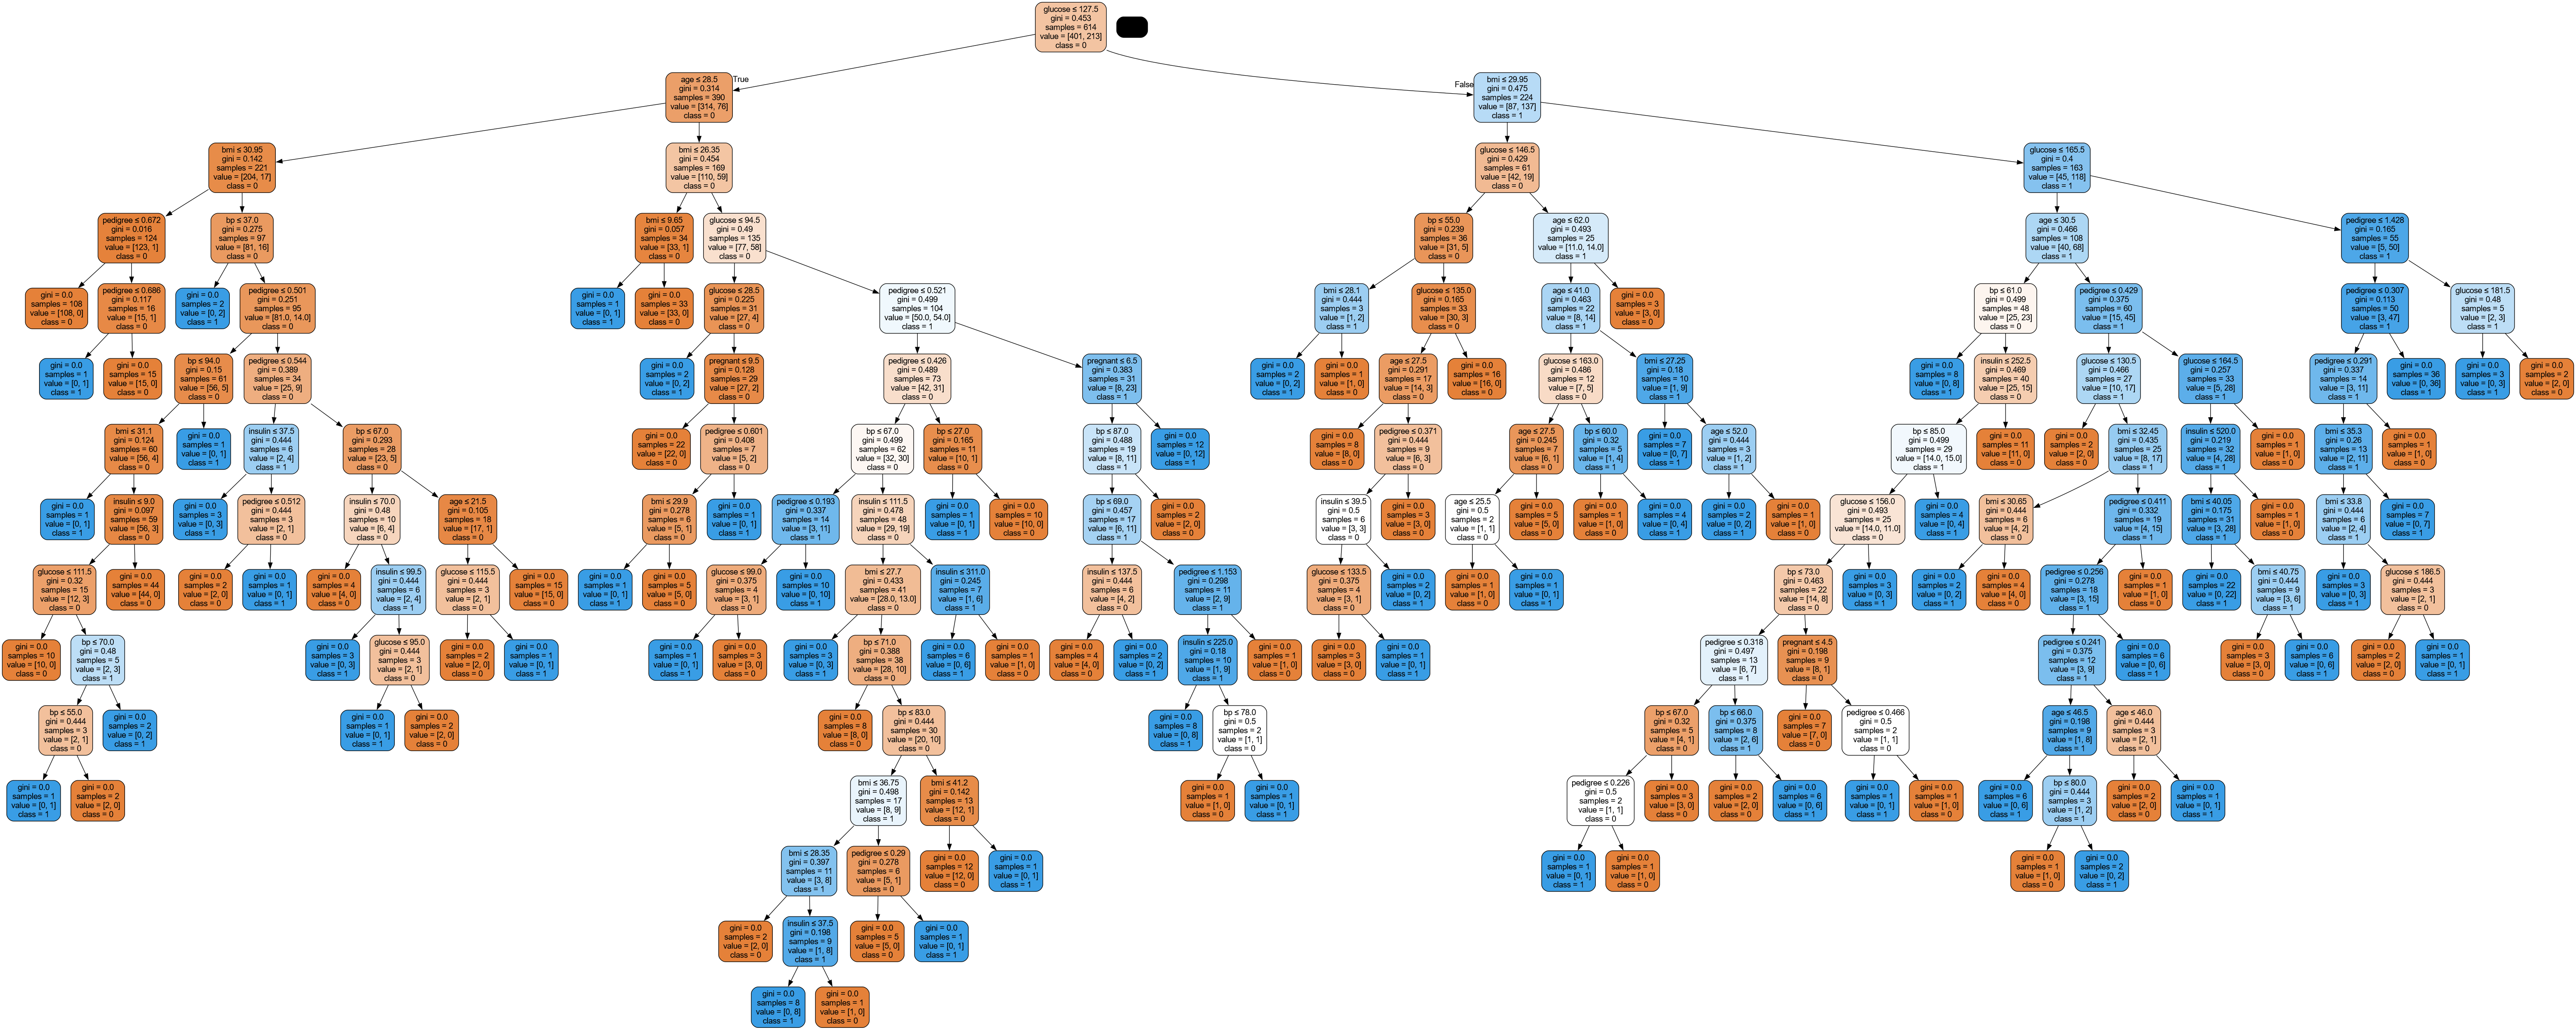

In [16]:
# Assuming clf is your trained classifier and feature_cols is a list of feature names
dot_data = StringIO()
export_graphviz(clf, out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True, feature_names=feature_cols, class_names=['0', '1'])

# Create graph from the dot data
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())

# Save the graph as a PNG file
graph.write_png('diabetes.png')

# Display the image
Image(filename='diabetes.png')  # For Jupyter or displaying in notebook

**Optimizing Decision Tree Performance**  
*criterion* : optional (default=”gini”) or Choose attribute selection measure. This parameter allows us to use the different-different attribute selection measure. Supported criteria are “gini” for the Gini index and “entropy” for the information gain.

*splitter* : string, optional (default=”best”) or Split Strategy. This parameter allows us to choose the split strategy. Supported strategies are “best” to choose the best split and “random” to choose the best random split.

*max_depth *: int or None, optional (default=None) or Maximum Depth of a Tree. The maximum depth of the tree. If None, then nodes are expanded until all the leaves contain less than min_samples_split samples. The higher value of maximum depth causes overfitting, and a lower value causes underfitting (Source).

In Scikit-learn, optimization of decision tree classifier performed by only pre-pruning. Maximum depth of the tree can be used as a control variable for pre-pruning. In the following the example, you can plot a decision tree on the same data with max_depth=3. Other than pre-pruning parameters, You can also try other attribute selection measure such as entropy.

In [20]:
# Create Decision Tree classifer object
clf = DecisionTreeClassifier(criterion="entropy", max_depth=3)

# Train Decision Tree Classifer
clf = clf.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
print("Accuracy:",metrics.accuracy_score(y_test, y_pred))


Accuracy: 0.7662337662337663


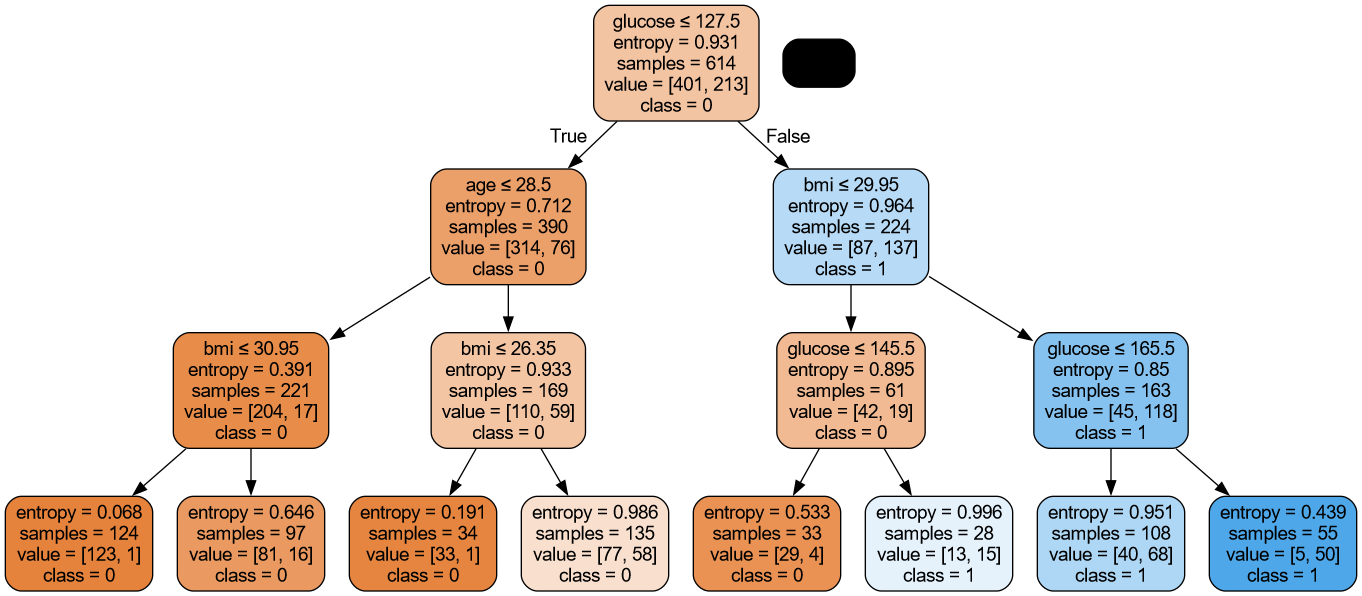

In [21]:
dot_data = StringIO()
export_graphviz(clf, out_file=dot_data,
                filled=True, rounded=True,
                special_characters=True, feature_names = feature_cols,class_names=['0','1'])
graph = pydotplus.graph_from_dot_data(dot_data.getvalue())
graph.write_png('diabetes.png')
Image(graph.create_png())

### Hyperparameter Tuning using GridSearch
While you can adjust the hyperparameters manually until you find a great combination of hyperparameter values, this can be tedious.

Instead, you could use Scikit-Learn's `GridSearchCV` to search for you. All you need to do is tell it which hyperparameters you want it to experiment with, and what values to try out, and it will evaluate all the possible combinations of hyperparameter values, using cross-validation.

In [40]:
from sklearn.model_selection import GridSearchCV

dt_classifier = DecisionTreeClassifier(random_state=42)

# Define the parameter grid to search
param_grid = {
    # try 3x5×3 combinations of hyperparameters
    'criterion': ["gini", "entropy", "log_loss"],
    'max_depth': [1,3,5,7,10],
    'min_samples_split': [2,3,7]
}

# train across 5 folds
grid_search = GridSearchCV(dt_classifier, param_grid, cv=5,
                           scoring='accuracy', return_train_score=True)
grid_search.fit(X_test, y_test)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy', ...], 'max_depth': [1, 3, ...], 'min_samples_split': [2, 3, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of th

In [41]:
### Return back the best parameter
grid_search.best_params_

{'criterion': 'gini', 'max_depth': 1, 'min_samples_split': 2}

In [42]:
# Create Hyperparameter tune Decision Tree classifer object
hp_classifier = DecisionTreeClassifier(criterion="gini", max_depth = 1, min_samples_split = 2)

# Train Decision Tree Classifer
hp_classifier.fit(X_train,y_train)

#Predict the response for test dataset
y_pred = hp_classifier.predict(X_test)

# Model Accuracy, how often is the classifier correct?
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))

Accuracy: 0.7402597402597403
